In [1]:
import pandas as pd

In [3]:
df_ursf = pd.read_excel('../../03_data_raw/exploration_inputs/etablissements-et-effectifs-salaries-au-niveau-commune-x-ape-last.xlsx')
df_ursf


,Région,Ancienne région,Département,Zone d'emploi,EPCI,Nom commune,Commune,Grand secteur d'activité,Secteur NA17,Secteur NA38,...,Nombre d'établissements 2020,Effectifs salariés 2020,Nombre d'établissements 2021,Effectifs salariés 2021,Nombre d'établissements 2022,Effectifs salariés 2022,Nombre d'établissements 2023,Effectifs salariés 2023,Nombre d'établissements 2024,Effectifs salariés 2024
0,Nouvelle-Aquitaine,Aquitaine,Pyrénées-Atlantiques,Pau,Communauté de communes du Nord Est Béarn,Ouillon,64438 Ouillon,GS1 Industrie,C4 Fabrication de matériels de transport,CL Fabrication de matériels de transport,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Nouvelle-Aquitaine,Poitou-Charentes,Vienne,Poitiers,Communauté urbaine du Grand Poitiers,Coulombiers,86083 Coulombiers,GS1 Industrie,C4 Fabrication de matériels de transport,CL Fabrication de matériels de transport,...,1.0,12.0,1.0,11.0,1.0,10.0,1.0,10.0,1.0,10.0
2,Grand Est,Lorraine,Moselle,Metz,Communauté de communes Rives de Moselle,Richemont,57582 Richemont,GS1 Industrie,C4 Fabrication de matériels de transport,CL Fabrication de matériels de transport,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Bretagne,Bretagne,Ille-et-Vilaine,Rennes,Communauté de communes Liffré-Cormier Communauté,Liffré,35152 Liffré,GS1 Industrie,C4 Fabrication de matériels de transport,CL Fabrication de matériels de transport,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Nouvelle-Aquitaine,Poitou-Charentes,Vienne,Poitiers,Communauté de communes Vienne et Gartempe,Montmorillon,86165 Montmorillon,GS1 Industrie,C4 Fabrication de matériels de transport,CL Fabrication de matériels de transport,...,2.0,66.0,2.0,68.0,1.0,67.0,1.0,72.0,1.0,68.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2736,Auvergne-Rhône-Alpes,Rhône-Alpes,Drôme,Valence,Communauté d'agglomération Valence Romans Agglo,Chabeuil,26064 Chabeuil,GS1 Industrie,C4 Fabrication de matériels de transport,CL Fabrication de matériels de transport,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2737,Normandie,Haute-Normandie,Eure,Rouen,Communauté d'agglomération Seine-Eure,Les Damps,27196 Les Damps,GS1 Industrie,C4 Fabrication de matériels de transport,CL Fabrication de matériels de transport,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2738,Nouvelle-Aquitaine,Poitou-Charentes,Vienne,Saint-Junien,Communauté de communes Vienne et Gartempe,Le Vigeant,86289 Le Vigeant,GS1 Industrie,C4 Fabrication de matériels de transport,CL Fabrication de matériels de transport,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2739,Auvergne-Rhône-Alpes,Rhône-Alpes,Isère,Voiron,Communauté de communes Saint-Marcellin Vercors...,Chatte,38095 Chatte,GS1 Industrie,C4 Fabrication de matériels de transport,CL Fabrication de matériels de transport,...,1.0,163.0,1.0,169.0,1.0,158.0,1.0,158.0,1.0,151.0


In [7]:
df_ursf['Département'].describe()

count     2741
unique     100
top       Nord
freq        97
Name: Département, dtype: object

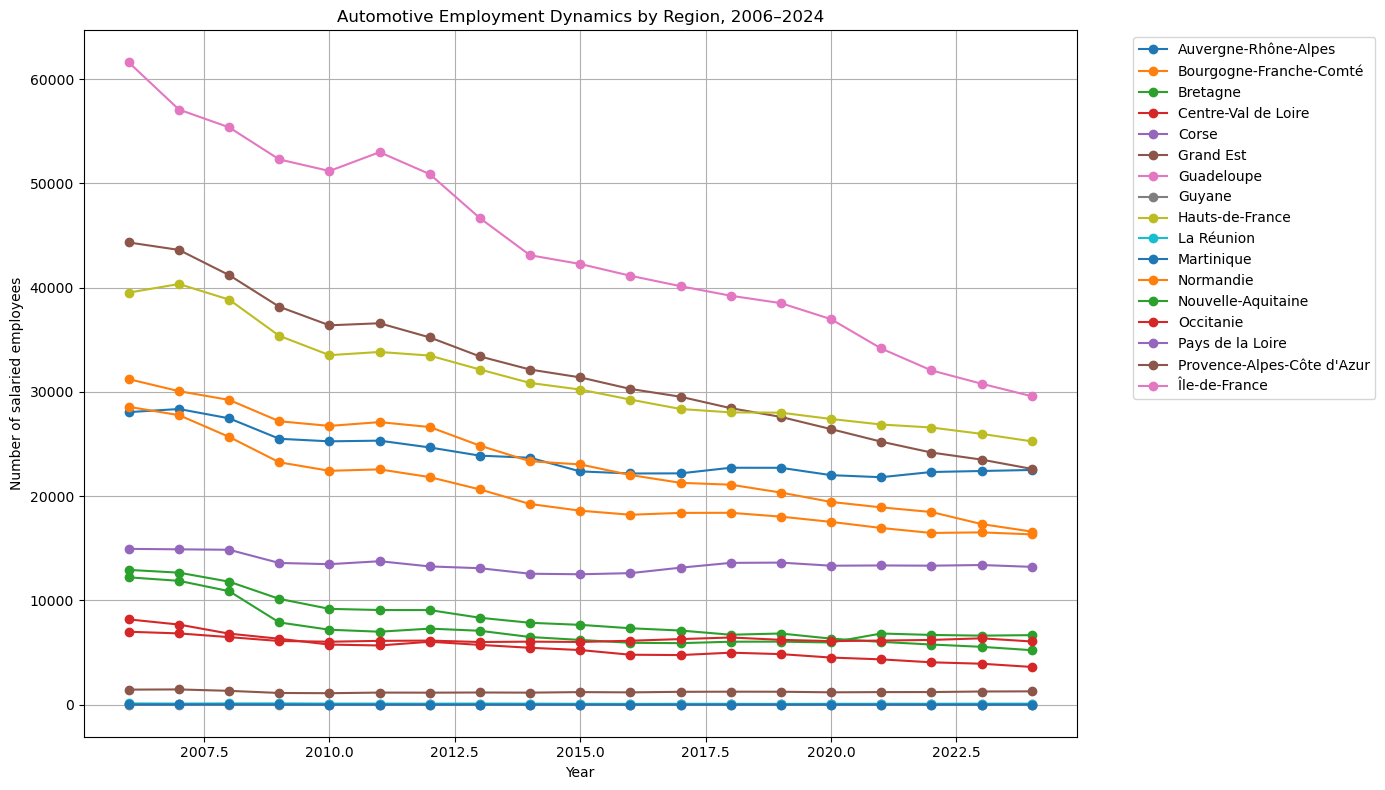

                        Région     2006     2024  Change_2006_2024  \
10                  Martinique     15.0      6.0              -9.0   
2                     Bretagne  12921.0   5220.0           -7701.0   
3          Centre-Val de Loire   8173.0   3613.0           -4560.0   
16               Île-de-France  61590.0  29578.0          -32012.0   
4                        Corse     20.0     10.0             -10.0   
5                    Grand Est  44324.0  22609.0          -21715.0   
1      Bourgogne-Franche-Comté  31214.0  16595.0          -14619.0   
12          Nouvelle-Aquitaine  12207.0   6665.0           -5542.0   
11                   Normandie  28559.0  16327.0          -12232.0   
8              Hauts-de-France  39515.0  25251.0          -14264.0   
0         Auvergne-Rhône-Alpes  28054.0  22505.0           -5549.0   
9                   La Réunion    113.0     95.0             -18.0   
13                   Occitanie   6988.0   6056.0            -932.0   
15  Provence-Alpes-C

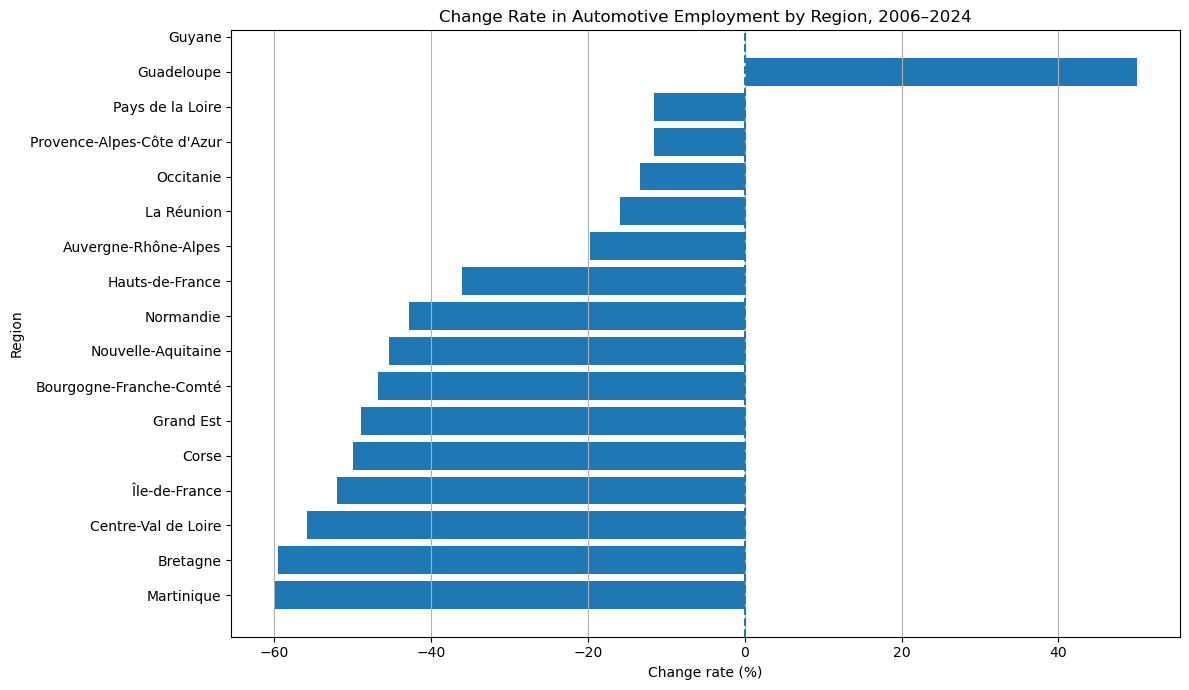

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
# Identify employment columns
employment_cols = [
    col for col in df_ursf.columns
    if "Effectifs salariés" in col
]

# Extract years from column names
years = [int(col.split()[-1]) for col in employment_cols]

# Aggregate employment by region
region_employment = (
    df_ursf.groupby("Région")[employment_cols]
      .sum()
      .reset_index()
)

# Rename columns from "Effectifs salariés 2006" to 2006, etc.
rename_dict = {
    col: int(col.split()[-1])
    for col in employment_cols
}

region_employment = region_employment.rename(columns=rename_dict)

# Convert to long format for plotting
region_long = region_employment.melt(
    id_vars="Région",
    value_vars=years,
    var_name="Year",
    value_name="Employment"
)

# ----------------------------------------------------
# 1. Plot employment dynamics over time by region
# ----------------------------------------------------

plt.figure(figsize=(14, 8))

for region in region_long["Région"].unique():
    data = region_long[region_long["Région"] == region]
    plt.plot(
        data["Year"],
        data["Employment"],
        marker="o",
        label=region
    )

plt.title("Automotive Employment Dynamics by Region, 2006–2024")
plt.xlabel("Year")
plt.ylabel("Number of salaried employees")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()


# ----------------------------------------------------
# 2. Calculate change rate between 2006 and 2024
# ----------------------------------------------------

region_employment["Change_2006_2024"] = (
    region_employment[2024] - region_employment[2006]
)

region_employment["Change_rate_2006_2024_%"] = (
    (region_employment[2024] - region_employment[2006])
    / region_employment[2006]
    * 100
)

# Keep only useful columns
change_region = region_employment[
    ["Région", 2006, 2024, "Change_2006_2024", "Change_rate_2006_2024_%"]
].copy()

# Sort by change rate
change_region = change_region.sort_values(
    "Change_rate_2006_2024_%"
)

print(change_region)


# ----------------------------------------------------
# 3. Bar chart of change rate by region
# ----------------------------------------------------

plt.figure(figsize=(12, 7))

plt.barh(
    change_region["Région"],
    change_region["Change_rate_2006_2024_%"]
)

plt.axvline(0, linestyle="--")
plt.title("Change Rate in Automotive Employment by Region, 2006–2024")
plt.xlabel("Change rate (%)")
plt.ylabel("Region")
plt.grid(axis="x")
plt.tight_layout()
plt.show()

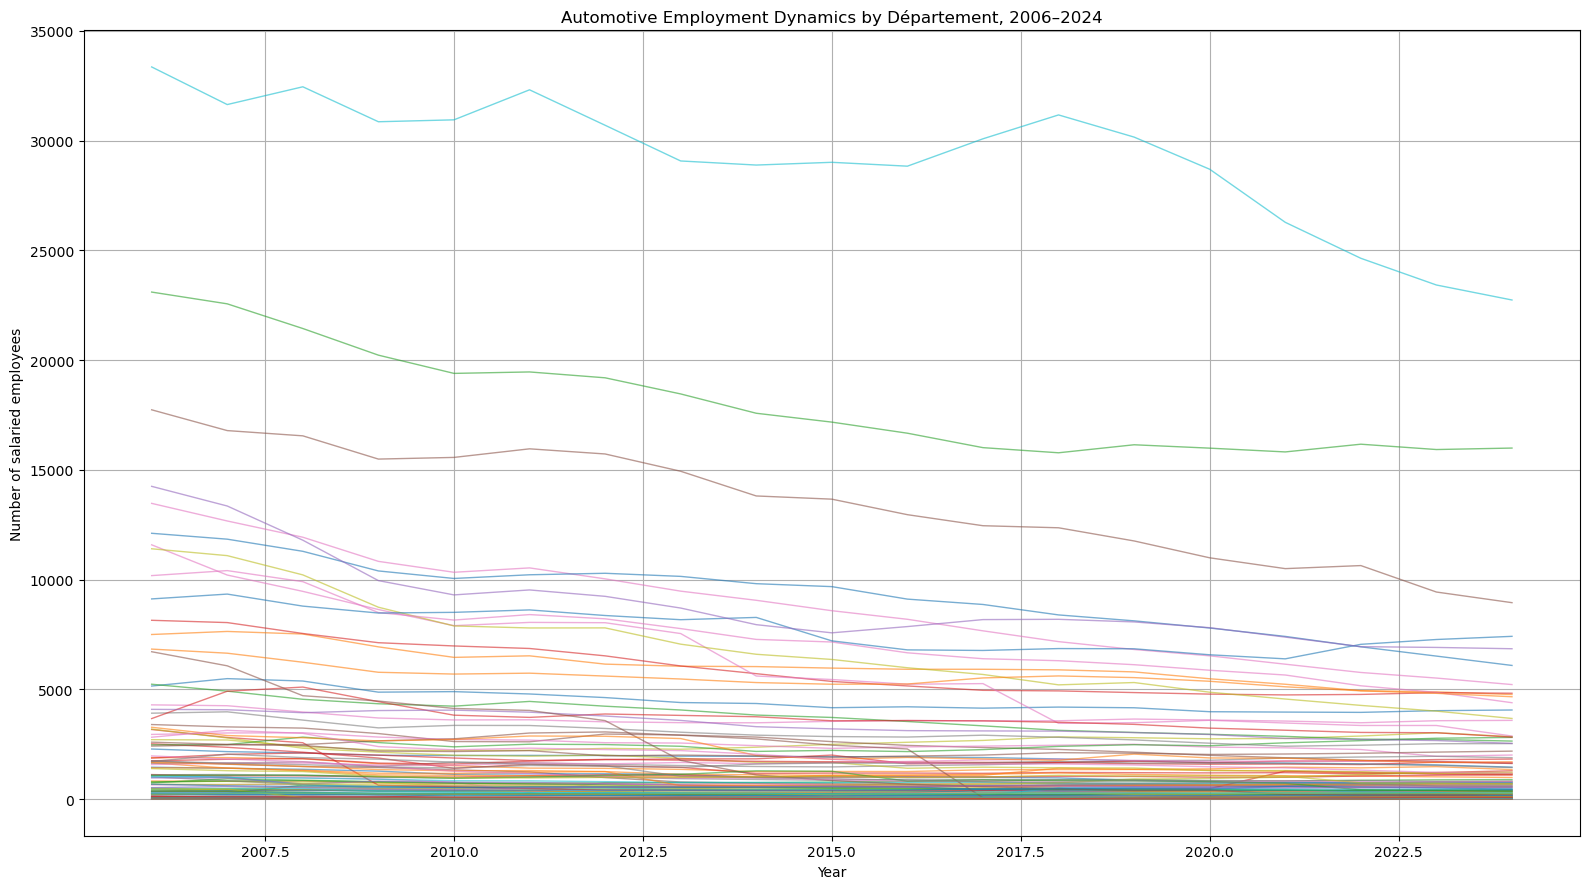

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Identify employment columns
employment_cols = [
    col for col in df_ursf.columns
    if "Effectifs salariés" in col
]

# Extract years
years = [int(col.split()[-1]) for col in employment_cols]

# Aggregate employment by département
dept_employment = (
    df_ursf.groupby("Département")[employment_cols]
           .sum()
           .reset_index()
)

# Rename employment columns from "Effectifs salariés 2006" to 2006, etc.
rename_dict = {
    col: int(col.split()[-1])
    for col in employment_cols
}

dept_employment = dept_employment.rename(columns=rename_dict)

# Convert to long format
dept_long = dept_employment.melt(
    id_vars="Département",
    value_vars=years,
    var_name="Year",
    value_name="Employment"
)

# ----------------------------------------------------
# 1. Employment dynamics over time by département
# ----------------------------------------------------

plt.figure(figsize=(16, 9))

for dept in dept_long["Département"].unique():
    data = dept_long[dept_long["Département"] == dept]
    plt.plot(
        data["Year"],
        data["Employment"],
        linewidth=1,
        alpha=0.6
    )

plt.title("Automotive Employment Dynamics by Département, 2006–2024")
plt.xlabel("Year")
plt.ylabel("Number of salaried employees")
plt.grid(True)
plt.tight_layout()
plt.show()

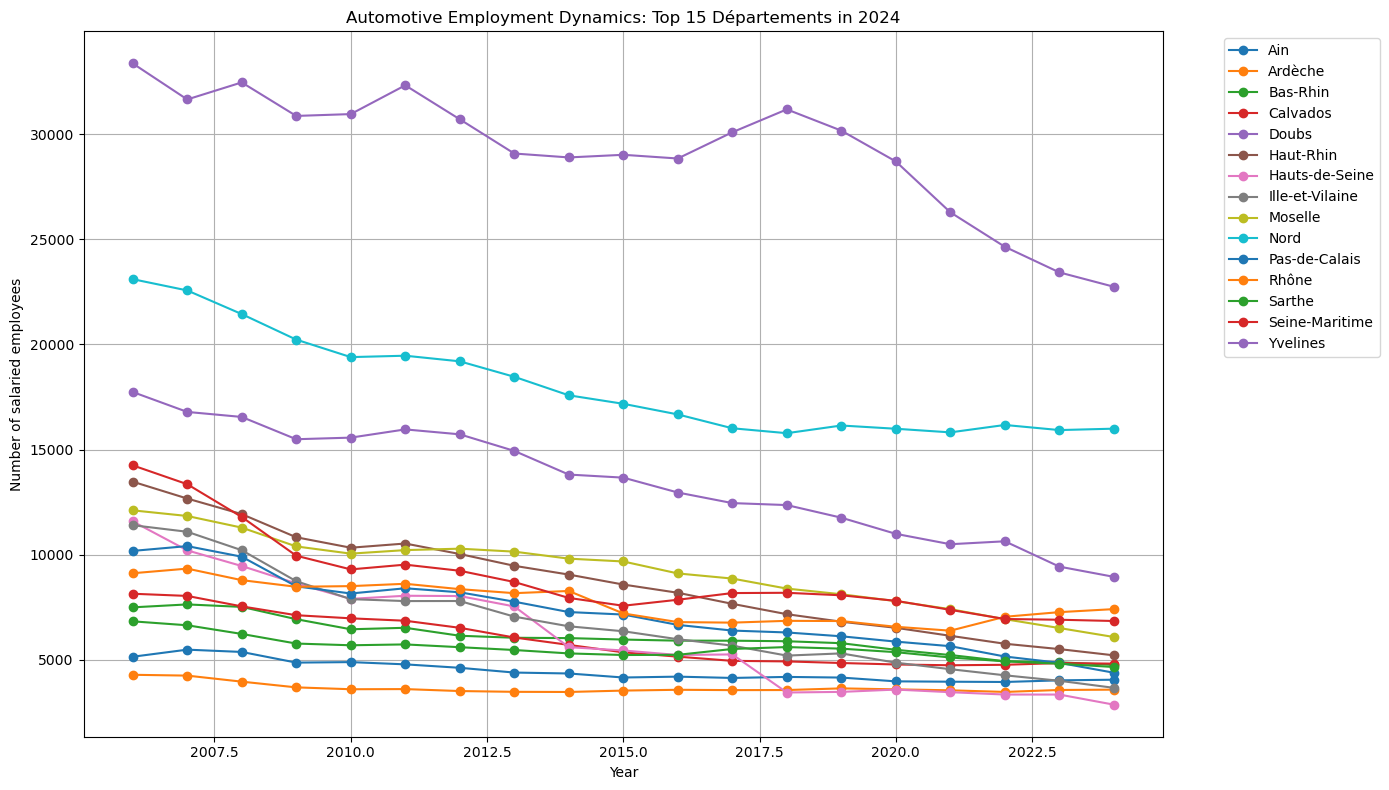

In [6]:
# Select top 15 départements by 2024 employment
top_depts = (
    dept_employment
    .sort_values(2024, ascending=False)
    .head(15)["Département"]
)

dept_long_top = dept_long[dept_long["Département"].isin(top_depts)]

plt.figure(figsize=(14, 8))

for dept in dept_long_top["Département"].unique():
    data = dept_long_top[dept_long_top["Département"] == dept]
    plt.plot(
        data["Year"],
        data["Employment"],
        marker="o",
        label=dept
    )

plt.title("Automotive Employment Dynamics: Top 15 Départements in 2024")
plt.xlabel("Year")
plt.ylabel("Number of salaried employees")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()

In [8]:
# Calculate absolute and percentage change
dept_employment["Change_2006_2024"] = (
    dept_employment[2024] - dept_employment[2006]
)

dept_employment["Change_rate_2006_2024_%"] = (
    (dept_employment[2024] - dept_employment[2006])
    / dept_employment[2006]
    * 100
)

# Keep useful columns
change_dept = dept_employment[
    ["Département", 2006, 2024, "Change_2006_2024", "Change_rate_2006_2024_%"]
].copy()

# Sort by change rate
change_dept = change_dept.sort_values("Change_rate_2006_2024_%")

change_dept

,Département,2006,2024,Change_2006_2024,Change_rate_2006_2024_%
85,Seine-Saint-Denis,6715.0,213.0,-6502.0,-96.827997
75,Paris,2595.0,107.0,-2488.0,-95.876686
78,Pyrénées-Atlantiques,484.0,109.0,-375.0,-77.479339
46,Hauts-de-Seine,11586.0,2874.0,-8712.0,-75.194200
5,Ardennes,1732.0,523.0,-1209.0,-69.803695
...,...,...,...,...,...
15,Charente,90.0,185.0,95.0,105.555556
2,Allier,264.0,730.0,466.0,176.515152
4,Alpes-de-Haute-Provence,13.0,51.0,38.0,292.307692
35,Guyane,0.0,1.0,1.0,inf


In [9]:
df_ursf.to_csv('../../03_data_raw/exploration_inputs/df_ursf.csv')

In [104]:
import pandas as pd
import plotly.express as px
import requests

# 1. Load your dataset

# 2. Aggregate the data by Region (e.g., total employees for 2024)
# We group by the 'Région' column and sum the employees
geo_df = df_ursf.groupby('Région')[["Effectifs salariés 2024"]].sum().reset_index()

# 3. Load the geographical boundaries (GeoJSON) for French Regions
# This public file contains the polygon shapes for all regions in France
geojson_url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/regions.geojson"
france_regions = requests.get(geojson_url).json()

# 4. Create the Choropleth map
fig = px.choropleth(
    geo_df,
    geojson=france_regions,
    locations='Région',                  # The column in your dataframe with region names
    featureidkey="properties.nom",       # The property in the GeoJSON that matches the region names
    color='Effectifs salariés 2024',     # The data to determine the color intensity
    color_continuous_scale="Viridis",    # The color scheme (Viridis goes from dark purple to bright yellow)
    title="Automotive Industry Employment by French Region (2024)",
    labels={'Effectifs salariés 2024': 'Employees'}
)

# 5. Focus the map strictly on the boundaries of France
fig.update_geos(fitbounds="locations", visible=False)

# 6. Display the interactive map
fig.write_html("regional_division_automotive_industry.html")
fig.show()

<interactive plotly figure removed to keep the file small; re-run the cell to see it>

In [81]:
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import requests

# ==========================================
# 1. Load the Regional Map (GeoJSON)
# ==========================================
# This file contains the shapes for all current French regions
geojson_url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/regions.geojson"
france_regions = requests.get(geojson_url).json()

# Extract a master list of all regions from the map to ensure a complete map
all_regions = [{'Reg_Name': f['properties']['nom']} for f in france_regions['features']]
df_all_regions = pd.DataFrame(all_regions)

# ==========================================
# 2. Prepare Dataset 1: URSSAF Regional Data
# ==========================================
# df_ursf = pd.read_csv("df_ursf.csv")
# Group by Region and sum the 2024 workforce
ursf_data = df_ursf.groupby('Région')[["Effectifs salariés 2024"]].sum().reset_index()

# Merge with master list and fill missing with 0
df_ursf_full = pd.merge(df_all_regions, ursf_data, left_on='Reg_Name', right_on='Région', how='left')
df_ursf_full['Effectifs salariés 2024'] = df_ursf_full['Effectifs salariés 2024'].fillna(0)

# ==========================================
# 3. Prepare Dataset 2: Car Plants Regional Data
# ==========================================
df_plants = pd.read_excel("../../03_data_raw/exploration_inputs/plants_with_departments.xlsx")

# Mapping Departments to Regions (Standard French Administrative Mapping)
dept_to_region = {
    'Meurthe-et-Moselle': 'Grand Est', 'Moselle': 'Grand Est', 'Haut-Rhin': 'Grand Est', 'Ardennes': 'Grand Est',
    'Seine-Maritime': 'Normandie', 'Eure': 'Normandie', 'Calvados': 'Normandie',
    'Nord': 'Hauts-de-France', 'Pas-de-Calais': 'Hauts-de-France',
    'Sarthe': 'Pays de la Loire', 'Rhône': 'Auvergne-Rhône-Alpes', 'Allier': 'Auvergne-Rhône-Alpes',
    'Yvelines': 'Île-de-France', 'Doubs': 'Bourgogne-Franche-Comté', 'Haute-Saône': 'Bourgogne-Franche-Comté',
    'Ille-et-Vilaine': 'Bretagne'
}

df_plants['Region'] = df_plants['Department'].map(dept_to_region)
# Sum up only the valid reported employees per region
plants_valid = df_plants.dropna(subset=['employees']).groupby('Region')['employees'].sum().reset_index()

# Merge with master list and fill missing with 0
df_plants_full = pd.merge(df_all_regions, plants_valid, left_on='Reg_Name', right_on='Region', how='left')
df_plants_full['employees'] = df_plants_full['employees'].fillna(0)

# ==========================================
# 4. Create the Side-by-Side Plotly Figure
# ==========================================
fig = make_subplots(
    rows=1, cols=2, 
    specs=[[{"type": "choropleth"}, {"type": "choropleth"}]],
    subplot_titles=("Total Auto Sector (URSSAF)", "Specific Plants")
)

# Left Map: URSSAF Total Sector
fig.add_trace(
    go.Choropleth(
        geojson=france_regions,
        locations=df_ursf_full['Reg_Name'],
        z=df_ursf_full['Effectifs salariés 2024'],
        featureidkey="properties.nom",
        colorscale="Plasma",
        text=df_ursf_full['Reg_Name'],
        hovertemplate="<b>%{text}</b><br>Total Sector: %{z}<extra></extra>",
        colorbar_title="Total",
        colorbar=dict(x=0.45)
    ),
    row=1, col=1
)

# Right Map: Specific Plants
fig.add_trace(
    go.Choropleth(
        geojson=france_regions,
        locations=df_plants_full['Reg_Name'],
        z=df_plants_full['employees'],
        featureidkey="properties.nom",
        colorscale="Reds",
        text=df_plants_full['Reg_Name'],
        hovertemplate="<b>%{text}</b><br>Plant Workforce: %{z}<extra></extra>",
        colorbar_title="Plants",
        colorbar=dict(x=1.0)
    ),
    row=1, col=2
)

# ==========================================
# 5. Final Layout Formatting
# ==========================================
fig.update_geos(fitbounds="locations", visible=False)

fig.update_layout(
    title_text="Regional Comparison: automotive industry vs. collected French plants",
    title_x=0.5,
    width=1200,
    height=600
)

# Save as HTML so you can open it in your browser
fig.write_html("regional_auto_comparison_map.html")
fig.show()

<interactive plotly figure removed to keep the file small; re-run the cell to see it>

In [102]:

fig.update_geos(fitbounds="locations", visible=False)

fig.update_layout(
    title_text="Regional Comparison: automotive industry vs. collected French plants",
    title_x=0.5,
    width=1200,
    height=600
)

fig.show()

fig.write_html("france_auto_employment_maps_region.html")

AttributeError: 'Figure' object has no attribute 'update_geos'

In [107]:
import pandas as pd
import plotly.express as px
import requests


df_ursf['Code département'] = df_ursf['Code département'].astype(str)

dept_df = df_ursf.groupby(['Code département', 'Département'])[["Effectifs salariés 2024"]].sum().reset_index()

geojson_url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements.geojson"
france_departments = requests.get(geojson_url).json()

fig = px.choropleth(
    dept_df,
    geojson=france_departments,
    locations='Code département',        # Use the department code for exact matching
    featureidkey="properties.code",      # Match with the 'code' property in the GeoJSON
    color='Effectifs salariés 2024',     # The data to determine the color intensity
    color_continuous_scale="Plasma",     # A different color scale (dark blue to bright yellow)
    hover_name='Département',            # Show the actual Department name when hovering
    title="Automotive Industry Employment by French Department (2024)",
    labels={'Effectifs salariés 2024': 'Employees', 'Code département': 'Dept Code'}
)

fig.update_geos(fitbounds="locations", visible=False)

#fig.show()
# fig.show()  <-- Comment this out!
fig.write_html("department_division_automotive_employment.html")

In [ ]:

geojson_url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements.geojson"
france_departments = requests.get(geojson_url).json()

# NEW: Extract a master list of ALL department codes and names directly from the map
all_depts = [{'Dept_Code': f['properties']['code'], 'Dept_Name': f['properties']['nom']} 
             for f in france_departments['features']]
df_all_depts = pd.DataFrame(all_depts)

# ==========================================
# 2. Prepare Dataset 1: URSSAF General Data
# ==========================================
# df_ursf = pd.read_csv("df_ursf.csv")
df_ursf['Code département'] = df_ursf['Code département'].astype(str)
dept_ursf = df_ursf.groupby('Code département')[["Effectifs salariés 2024"]].sum().reset_index()

# Merge with the master list to ensure all departments are present, fill missing with 0
df_ursf_full = pd.merge(df_all_depts, dept_ursf, left_on='Dept_Code', right_on='Code département', how='left')
df_ursf_full['Effectifs salariés 2024'] = df_ursf_full['Effectifs salariés 2024'].fillna(0)

# ==========================================
# 3. Prepare Dataset 2: Car Plants Data
# ==========================================
# df_plants = pd.read_csv("plants_with_departments.csv")
df_valid = df_plants.dropna(subset=['employees']).copy()

dept_to_code = {
    'Nord': '59', 'Seine-Maritime': '76', 'Yvelines': '78', 
    'Moselle': '57', 'Meurthe-et-Moselle': '54', 'Sarthe': '72', 
    'Rhône': '69', 'Pas-de-Calais': '62', 'Eure': '27', 
    'Doubs': '25', 'Haut-Rhin': '68', 'Ille-et-Vilaine': '35', 
    'Calvados': '14', 'Ardennes': '08', 'Allier': '03', 
    'Haute-Saône': '70'
}
df_valid['Dept_Code'] = df_valid['Department'].map(dept_to_code)
dept_plants = df_valid.groupby('Dept_Code')['employees'].sum().reset_index()

# Merge with the master list to ensure all departments are present, fill missing with 0
df_plants_full = pd.merge(df_all_depts, dept_plants, on='Dept_Code', how='left')
df_plants_full['employees'] = df_plants_full['employees'].fillna(0)

# ==========================================
# 4. Create the Side-by-Side Plotly Figure
# ==========================================
fig = make_subplots(
    rows=1, cols=2, 
    specs=[[{"type": "choropleth"}, {"type": "choropleth"}]],
    subplot_titles=("Total Auto Sector Employees (URSSAF)", "Specific Car Plant Employees")
)

# Add First Map (URSSAF Data)
fig.add_trace(
    go.Choropleth(
        geojson=france_departments,
        locations=df_ursf_full['Dept_Code'],
        z=df_ursf_full['Effectifs salariés 2024'],
        featureidkey="properties.code",
        colorscale="Plasma",
        text=df_ursf_full['Dept_Name'],
        hovertemplate="<b>%{text}</b><br>Employees: %{z}<extra></extra>",
        colorbar_title="URSSAF",
        colorbar=dict(x=0.45)
    ),
    row=1, col=1
)

# Add Second Map (Plant Data)
fig.add_trace(
    go.Choropleth(
        geojson=france_departments,
        locations=df_plants_full['Dept_Code'],
        z=df_plants_full['employees'],
        featureidkey="properties.code",
        colorscale="Reds",
        text=df_plants_full['Dept_Name'],
        hovertemplate="<b>%{text}</b><br>Plant Employees: %{z}<extra></extra>",
        colorbar_title="Plants",
        colorbar=dict(x=1.0)
    ),
    row=1, col=2
)

# ==========================================
# 5. Formatting and Display
# ==========================================
fig.update_geos(fitbounds="locations", visible=False)

fig.update_layout(
    title_text="Comparison: Regional Auto Sector Employment vs Major Assembly Plants",
    title_x=0.5,
    width=1200,
    height=600
)

fig.show()

<interactive plotly figure removed to keep the file small; re-run the cell to see it>

In [101]:
pip install --upgrade plotly

Note: you may need to restart the kernel to use updated packages.


In [ ]:

fig.update_geos(fitbounds="locations", visible=False)

fig.update_layout(
    title_text="Comparison: Regional Auto Sector Employment vs Major Assembly Plants",
    title_x=0.5,
    width=1200,
    height=600
)

fig.show()

fig.write_html("france_auto_employment_maps.html")

<interactive plotly figure removed to keep the file small; re-run the cell to see it>

In [24]:
sectors_to_keep = [
    "2910Z Construction de véhicules automobiles",
    "2920Z Fabrication de carrosseries et remorques",
    "2932Z Fabrication d'autres équipements automobiles"
]

df_filtered = df_ursf[df_ursf['APE'].isin(sectors_to_keep)].copy()

In [20]:
df_filtered

,Région,Ancienne région,Département,Zone d'emploi,EPCI,Nom commune,Commune,Grand secteur d'activité,Secteur NA17,Secteur NA38,...,Nombre d'établissements 2020,Effectifs salariés 2020,Nombre d'établissements 2021,Effectifs salariés 2021,Nombre d'établissements 2022,Effectifs salariés 2022,Nombre d'établissements 2023,Effectifs salariés 2023,Nombre d'établissements 2024,Effectifs salariés 2024
0,Nouvelle-Aquitaine,Aquitaine,Pyrénées-Atlantiques,Pau,Communauté de communes du Nord Est Béarn,Ouillon,64438 Ouillon,GS1 Industrie,C4 Fabrication de matériels de transport,CL Fabrication de matériels de transport,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Nouvelle-Aquitaine,Poitou-Charentes,Vienne,Poitiers,Communauté urbaine du Grand Poitiers,Coulombiers,86083 Coulombiers,GS1 Industrie,C4 Fabrication de matériels de transport,CL Fabrication de matériels de transport,...,1.0,12.0,1.0,11.0,1.0,10.0,1.0,10.0,1.0,10.0
3,Bretagne,Bretagne,Ille-et-Vilaine,Rennes,Communauté de communes Liffré-Cormier Communauté,Liffré,35152 Liffré,GS1 Industrie,C4 Fabrication de matériels de transport,CL Fabrication de matériels de transport,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Hauts-de-France,Nord-Pas-de-Calais,Pas-de-Calais,Lens,Communauté d'agglomération d'Hénin-Carvin,Courrières,62250 Courrières,GS1 Industrie,C4 Fabrication de matériels de transport,CL Fabrication de matériels de transport,...,1.0,1.0,1.0,4.0,1.0,8.0,1.0,8.0,1.0,10.0
6,Provence-Alpes-Côte d'Azur,Provence-Alpes-Côte d'Azur,Vaucluse,Cavaillon,Communauté d'agglomération Luberon Monts de Va...,Cavaillon,84035 Cavaillon,GS1 Industrie,C4 Fabrication de matériels de transport,CL Fabrication de matériels de transport,...,2.0,24.0,2.0,25.0,2.0,31.0,2.0,28.0,2.0,33.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2731,Nouvelle-Aquitaine,Aquitaine,Landes,Mont-de-Marsan,Mont de Marsan Agglomération,Mont-de-Marsan,40192 Mont-de-Marsan,GS1 Industrie,C4 Fabrication de matériels de transport,CL Fabrication de matériels de transport,...,1.0,19.0,1.0,16.0,1.0,14.0,1.0,13.0,1.0,13.0
2733,Auvergne-Rhône-Alpes,Rhône-Alpes,Loire,Saint-Étienne,Saint-Etienne Métropole,Unieux,42316 Unieux,GS1 Industrie,C4 Fabrication de matériels de transport,CL Fabrication de matériels de transport,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2736,Auvergne-Rhône-Alpes,Rhône-Alpes,Drôme,Valence,Communauté d'agglomération Valence Romans Agglo,Chabeuil,26064 Chabeuil,GS1 Industrie,C4 Fabrication de matériels de transport,CL Fabrication de matériels de transport,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2738,Nouvelle-Aquitaine,Poitou-Charentes,Vienne,Saint-Junien,Communauté de communes Vienne et Gartempe,Le Vigeant,86289 Le Vigeant,GS1 Industrie,C4 Fabrication de matériels de transport,CL Fabrication de matériels de transport,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [25]:
df_filtered['APE'].describe()

count                                               2599
unique                                                 3
top       2920Z Fabrication de carrosseries et remorques
freq                                                1544
Name: APE, dtype: object

In [31]:
test = df_ursf.duplicated()

In [32]:
test.describe()

count      2741
unique        1
top       False
freq       2741
dtype: object

In [ ]:
target_city = "Vesoul"  
year_column = "Effectifs salariés 2019"
df_commune = df_ursf[df_ursf['Nom commune'] == target_city]
total_employees = df_commune[year_column].sum()
total_employees

6820.0

In [70]:
# 1. Load both datasets
df_ursf = pd.read_excel("../../03_data_raw/exploration_inputs/etablissements-et-effectifs-salaries-au-niveau-commune-x-ape-last.xlsx")
df_plants = pd.read_excel("../../03_data_raw/exploration_inputs/plants_with_departments.xlsx")

# 2. Clean the 'City' column in the small dataset 
# (e.g., turns "Sausheim, Mulhouse" into just "Sausheim")
df_plants['Commune_Clean'] = df_plants['City'].str.split(', ').str[0]

# 3. Filter to get only the rows where there is a valid employment number given
df_plants_valid = df_plants.dropna(subset=['employees']).copy()

# 4. Prepare a list to store the final matched rows
results = []

# 5. Loop through each specific plant to find it in the URSSAF dataset
for index, row in df_plants_valid.iterrows():
    commune = row['Commune_Clean']
    plant_emp = row['employees']
    year = int(row['year'])
    
    # Check the year: URSSAF data only goes up to 2024.
    # If the plant year is 2025 or higher, we use 2024 as the closest match.
    ursf_year = 2024 if year > 2024 else year
    year_col = f"Effectifs salariés {ursf_year}"
    
    # Filter URSSAF dataset to find exact matches for this specific commune
    match_ursf = df_ursf[df_ursf['Nom commune'] == commune]
    
    if not match_ursf.empty:
        # Sum the employment numbers from the URSSAF dataset for the corresponding year
        ursf_emp_sum = match_ursf[year_col].sum()
        
        results.append({
            'Commune': commune,
            'Year_Reported': year,
            'Plant_Employees': plant_emp,
            'URSSAF_Total': ursf_emp_sum,
            'URSSAF_Year_Used': ursf_year
        })
    else:
        # If no match is found (e.g. spelling difference), set URSSAF Total to 0
        results.append({
            'Commune': commune,
            'Year_Reported': year,
            'Plant_Employees': plant_emp,
            'URSSAF_Total': 0,
            'URSSAF_Year_Used': ursf_year
        })

# 6. Convert the results back into a clean Dataframe and display it!
df_results = pd.DataFrame(results)

# Optional: You can export this directly to a CSV if you want to keep the matched data
df_results.to_csv("matched_plant_urssaf_employment.csv", index=False)

print(df_results.to_string(index=False))

              Commune  Year_Reported  Plant_Employees  URSSAF_Total  URSSAF_Year_Used
              Batilly           2025           1938.0        2070.0              2024
                Cléon           2025           3124.0        3292.0              2024
               Dieppe           2025            380.0         376.0              2024
                Douai           2025           4265.0        4534.0              2024
              Le Mans           2024           2000.0        2083.0              2024
             Maubeuge           2025           1835.0        1918.0              2024
              Meyzieu           2025            106.0         107.0              2024
                Ruitz           2025            331.0         810.0              2024
          Sandouville           2025           1865.0        2038.0              2024
                Flins           2023           1941.0        2147.0              2023
Saint André de l'Eure           2025            360.0 

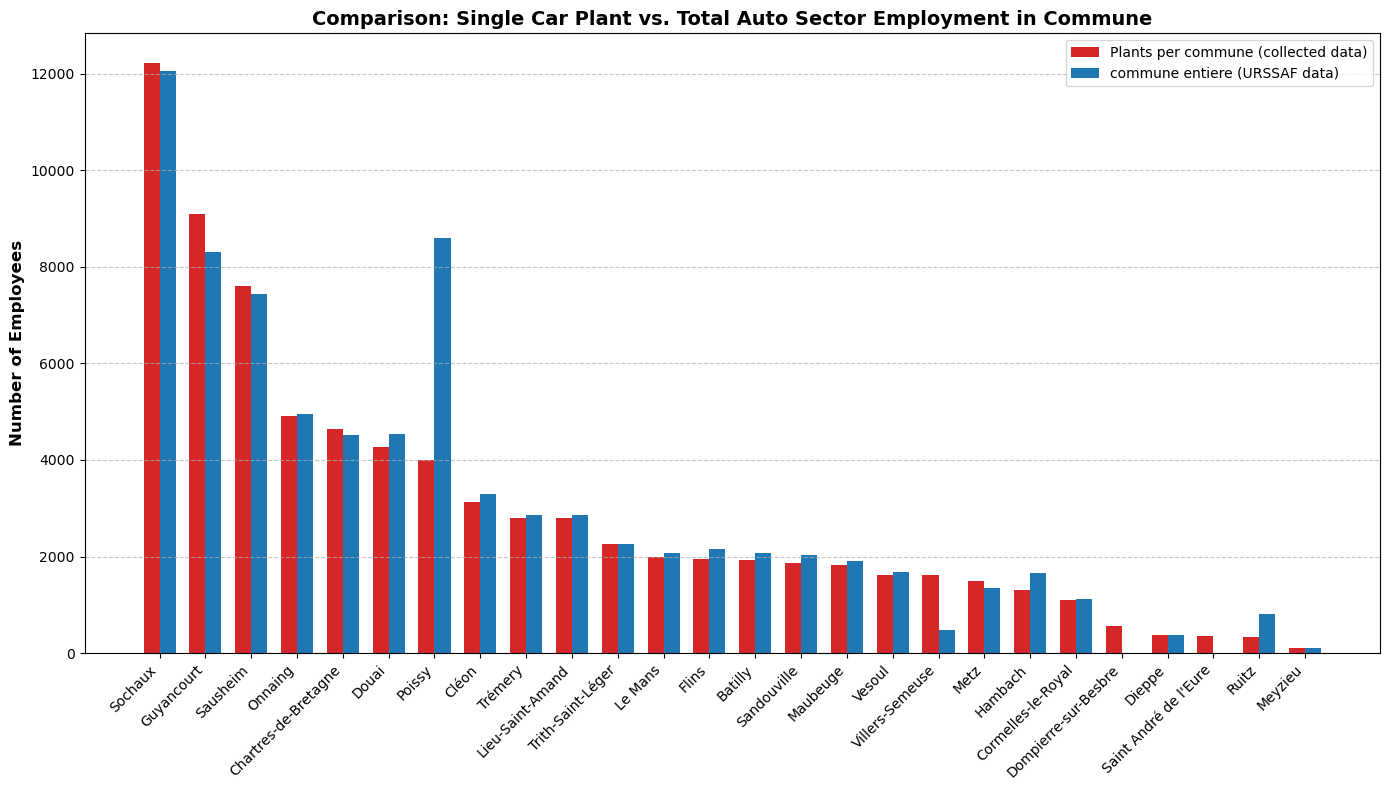

In [92]:

# 1. Load the dataset
# df_results = pd.read_csv("matched_plant_urssaf_employment.csv")

# =====================================================================
# 2. THE FIX: Sort by Plant_Employees in descending order
# =====================================================================
df_results = df_results.sort_values(by='Plant_Employees', ascending=False).reset_index(drop=True)

# 3. Set up the figure size
fig, ax = plt.subplots(figsize=(14, 8))

# 4. Define bar width and the x-axis positions for each city
x = np.arange(len(df_results['Commune']))
width = 0.35

# 5. Plot the two sets of bars side-by-side
ax.bar(x - width/2, df_results['Plant_Employees'], width, label='Plants per commune (collected data)', color='tab:red')
ax.bar(x + width/2, df_results['URSSAF_Total'], width, label='commune entiere (URSSAF data)', color='tab:blue')

# 6. Add labels, title, and custom tick marks
ax.set_ylabel('Number of Employees', fontweight='bold', fontsize=12)
ax.set_title('Comparison: Single Car Plant vs. Total Auto Sector Employment in Commune', fontweight='bold', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(df_results['Commune'], rotation=45, ha='right', fontsize=10)
ax.legend()

# 7. Add a subtle grid to the background
ax.grid(axis='y', linestyle='--', alpha=0.7)

# 8. Adjust layout and display!
fig.tight_layout()
plt.show()

In [55]:
df_ursf.loc[
    (df_ursf["Zone d'emploi"] == "Douai") &
    (df_ursf["Nom commune"] != "Douai"),
    "Nom commune"
] = "Douai"

In [56]:
df_ursf.loc[
    df_ursf["Zone d'emploi"] == "Douai",
    ["Zone d'emploi", "Nom commune"]
].drop_duplicates()

,Zone d'emploi,Nom commune
52,Douai,Douai


/opt/anaconda3/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:226: UserWarning:

Workbook contains no default style, apply openpyxl's default

/opt/anaconda3/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:226: UserWarning:

Workbook contains no default style, apply openpyxl's default



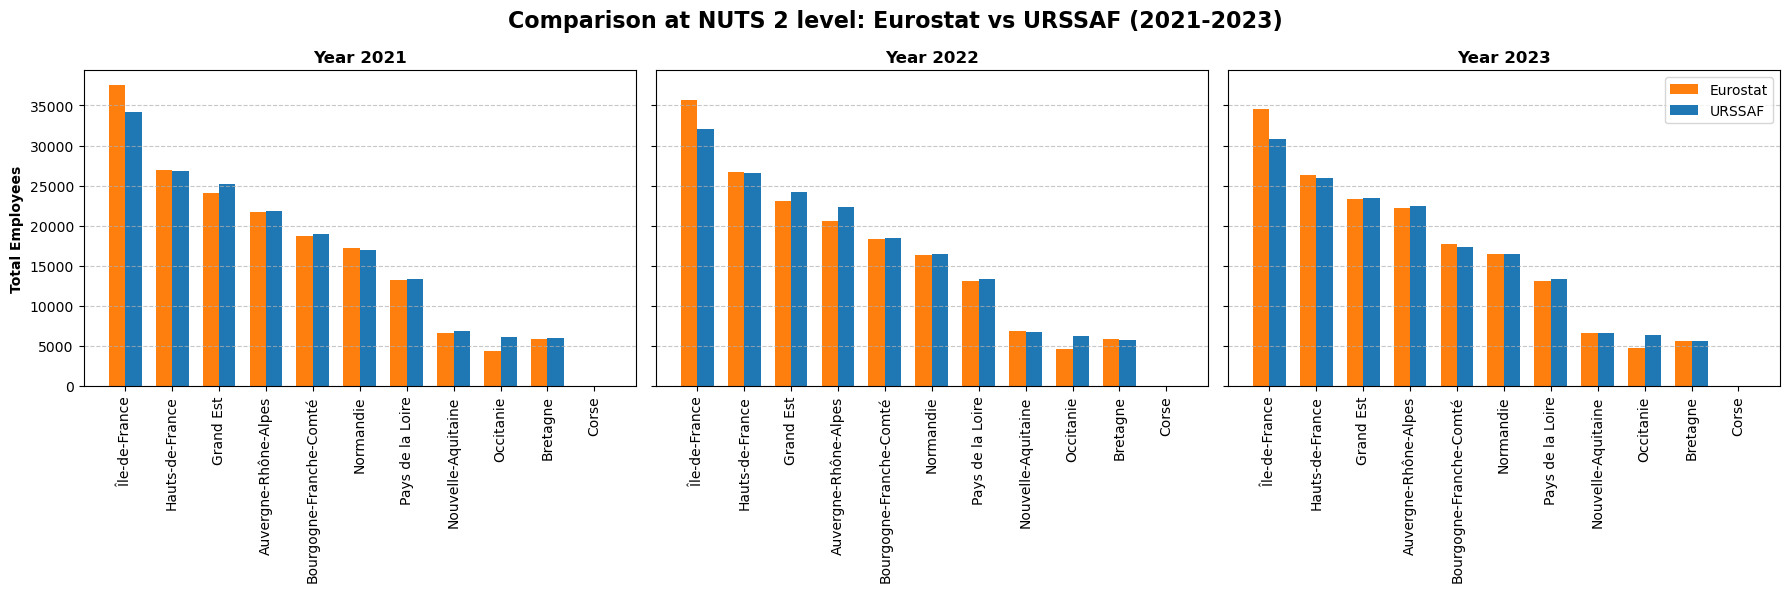

In [94]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. Helper function to load and clean Eurostat sheets
# ==========================================
def clean_sheet(filepath, sheet_name, metric_name):
    df = pd.read_excel(filepath, sheet_name=sheet_name, skiprows=8)
    df = df.rename(columns={'TIME': 'GEO (Codes)', 'TIME.1': 'GEO (Labels)'})
    df = df.drop(0).reset_index(drop=True)
    df = df[['GEO (Codes)', 'GEO (Labels)', '2021', '2022', '2023']]
    
    # Clean the Eurostat flags (e.g., removing ':', letters, spaces)
    for col in ['2021', '2022', '2023']:
        df[col] = df[col].astype(str).str.strip()
        # Keep only digits and the decimal point
        df[col] = df[col].str.replace(r'[a-zA-Z\s]+', '', regex=True)
        df[col] = df[col].replace(':', '')
        df[col] = pd.to_numeric(df[col], errors='coerce')
        
    # Melt into long format
    return df.melt(
        id_vars=['GEO (Codes)', 'GEO (Labels)'], 
        value_vars=['2021', '2022', '2023'], 
        var_name='Year', 
        value_name=metric_name
    )

# ==========================================
# 2. Process Eurostat Data and Multiply
# ==========================================
path = "../../03_data_raw/exploration_inputs/sbs_r_nuts2021__custom_21203869_spreadsheet.xlsx"
df1 = clean_sheet(path, "Sheet 1", "Persons employed per local unit")
df2 = clean_sheet(path, "Sheet 2", "Local units")
eurostat_df = pd.merge(df1, df2, on=['GEO (Codes)', 'GEO (Labels)', 'Year'], how='outer')

# Calculate Total Employment!
eurostat_df['Total_Eurostat'] = eurostat_df['Persons employed per local unit'] * eurostat_df['Local units']

# Filter only for French NUTS 2 regions (Code length 4 starting with FR)
euro_fr = eurostat_df[(eurostat_df['GEO (Codes)'].str.startswith('FR', na=False)) & (eurostat_df['GEO (Codes)'].str.len() == 4)].copy()

# Map Eurostat's NUTS 2 labels to match the exact spelling of URSSAF's "Ancienne région"
mapping_to_urssaf = {
    'Ile de France': 'Île-de-France', 'Centre - Val de Loire': 'Centre', 
    'Nord-Pas de Calais': 'Nord-Pas-de-Calais', 'Corse': 'Corse', 
    'Alsace': 'Alsace', 'Aquitaine': 'Aquitaine', 'Auvergne': 'Auvergne', 
    'Basse-Normandie': 'Basse-Normandie', 'Bourgogne': 'Bourgogne', 
    'Bretagne': 'Bretagne', 'Champagne-Ardenne': 'Champagne-Ardenne', 
    'Franche-Comté': 'Franche-Comté', 'Haute-Normandie': 'Haute-Normandie', 
    'Languedoc-Roussillon': 'Languedoc-Roussillon', 'Limousin': 'Limousin', 
    'Lorraine': 'Lorraine', 'Midi-Pyrénées': 'Midi-Pyrénées', 
    'Pays de la Loire': 'Pays de la Loire', 'Picardie': 'Picardie', 
    'Poitou-Charentes': 'Poitou-Charentes', "Provence-Alpes-Côte d'Azur": "Provence-Alpes-Côte d'Azur", 
    'Rhône-Alpes': 'Rhône-Alpes'
}
euro_fr['Ancienne région'] = euro_fr['GEO (Labels)'].map(mapping_to_urssaf)

# Group Eurostat totals by Region and Year
euro_grp = euro_fr.groupby(['Ancienne région', 'Year'])['Total_Eurostat'].sum().reset_index()

# ==========================================
# 3. Process URSSAF Data
# ==========================================
# df_ursf = pd.read_csv("df_ursf.csv")

# Extract the 3 years we care about and melt into long format
ursf_grp = df_ursf.groupby('Ancienne région')[['Effectifs salariés 2021', 'Effectifs salariés 2022', 'Effectifs salariés 2023']].sum().reset_index()
ursf_melt = ursf_grp.melt(id_vars=['Ancienne région'], value_vars=['Effectifs salariés 2021', 'Effectifs salariés 2022', 'Effectifs salariés 2023'], var_name='Year_col', value_name='Total_URSSAF')
ursf_melt['Year'] = ursf_melt['Year_col'].str.extract(r'(\d{4})')

# ==========================================
# 4. Merge and Roll up to Current Regions
# ==========================================
comp_df = pd.merge(euro_grp, ursf_melt[['Ancienne région', 'Year', 'Total_URSSAF']], on=['Ancienne région', 'Year'], how='inner')

# Create a dictionary from the URSSAF dataset that tells us which old regions belong to which current regions
new_region_mapping = df_ursf[['Ancienne région', 'Région']].drop_duplicates().set_index('Ancienne région')['Région'].to_dict()

# Apply the mapping and aggregate
comp_df['Région'] = comp_df['Ancienne région'].map(new_region_mapping)
comp_agg = comp_df.groupby(['Région', 'Year'])[['Total_Eurostat', 'Total_URSSAF']].sum().reset_index().fillna(0)

# ==========================================
# 5. Plotting the Comparison (1 Row, 3 Graphs)
# ==========================================
years = ['2021', '2022', '2023']

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

# Sort the regions visually from highest to lowest based on 2023 URSSAF totals
sort_order = comp_agg[comp_agg['Year'] == '2023'].sort_values('Total_URSSAF', ascending=False)['Région'].tolist()

for i, year in enumerate(years):
    ax = axes[i]
    # Filter for the specific year and sort
    data = comp_agg[comp_agg['Year'] == year].set_index('Région').reindex(sort_order).reset_index()
    
    x = np.arange(len(data['Région']))
    width = 0.35
    
    # Draw bars side-by-side
    ax.bar(x - width/2, data['Total_Eurostat'], width, label='Eurostat', color='tab:orange')
    ax.bar(x + width/2, data['Total_URSSAF'], width, label='URSSAF', color='tab:blue')
    
    ax.set_title(f'Year {year}', fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(data['Région'], rotation=90)
    
    if i == 0:
        ax.set_ylabel('Total Employees', fontweight='bold')
        
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
axes[2].legend(loc='upper right')
plt.suptitle('Comparison at NUTS 2 level: Eurostat vs URSSAF (2021-2023)', fontweight='bold', fontsize=16)

plt.tight_layout()
plt.show()

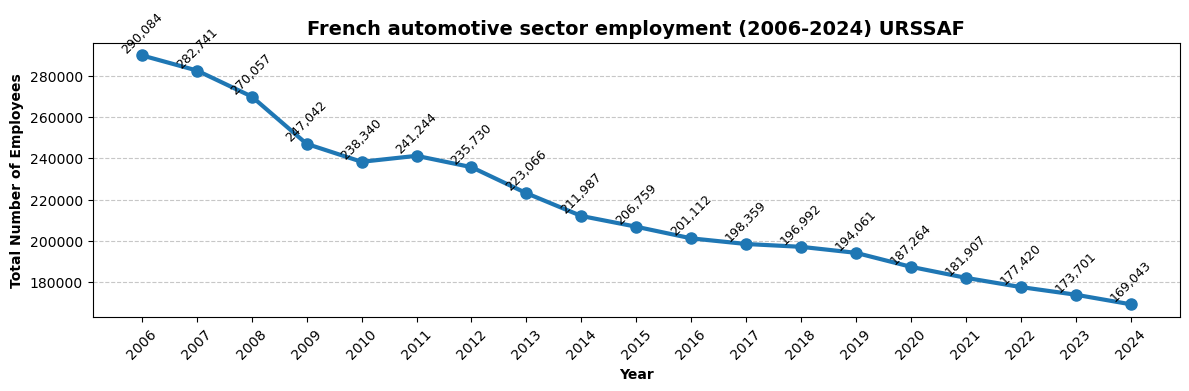

In [110]:
years = [str(y) for y in range(2006, 2025)]
emp_cols = [f"Effectifs salariés {y}" for y in years]

total_emp_by_year = df_ursf[emp_cols].sum()

plt.figure(figsize=(12, 4))
plt.plot(years, total_emp_by_year.values, marker='o', linewidth=3, color='tab:blue', markersize=8)

# Add employment numbers above each point
for year, value in zip(years, total_emp_by_year.values):
    plt.text(
        year,
        value,
        f"{value:,.0f}",
        ha='center',
        va='bottom',
        fontsize=9,
        rotation=45
    )

plt.title('French automotive sector employment (2006-2024) URSSAF', fontweight='bold', fontsize=14)
plt.xlabel('Year', fontweight='bold')
plt.ylabel('Total Number of Employees', fontweight='bold')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [120]:
df_euro.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  1 non-null      object
 1   Unnamed: 1  5 non-null      object
 2   Unnamed: 2  5 non-null      object
 3   Unnamed: 3  5 non-null      object
 4   Unnamed: 4  4 non-null      object
dtypes: object(5)
memory usage: 452.0+ bytes


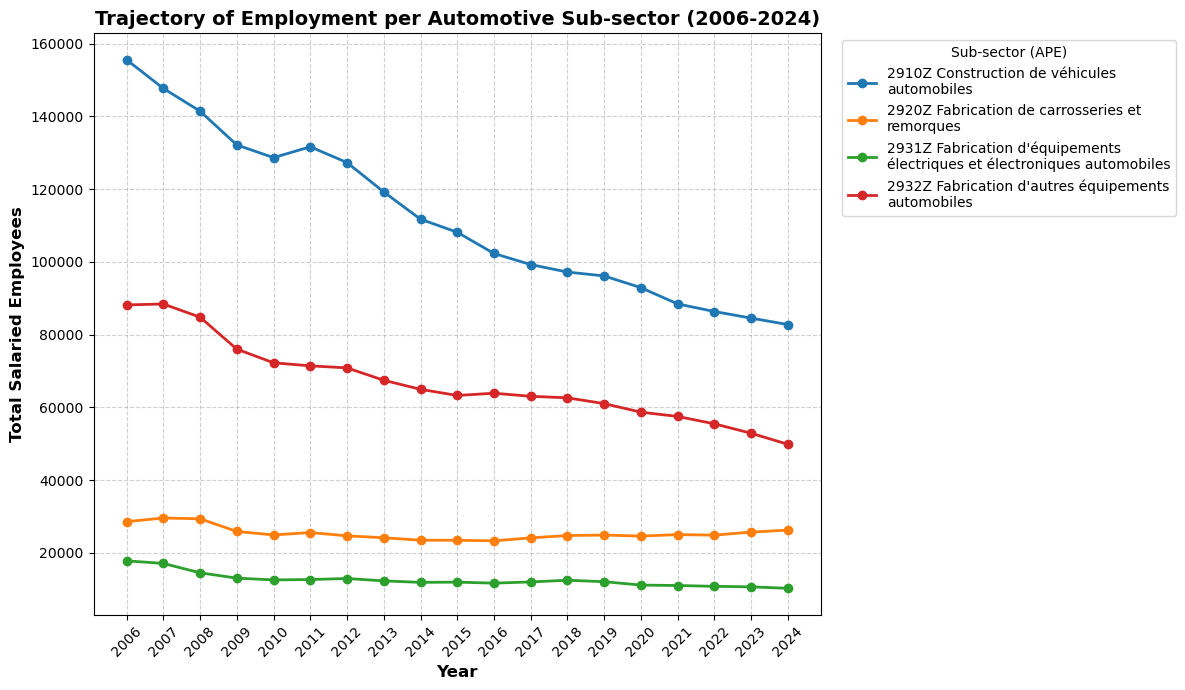

In [127]:
import pandas as pd
import matplotlib.pyplot as plt
import textwrap

# Load the dataset
file_path = '../../03_data_raw/exploration_inputs/etablissements-et-effectifs-salaries-au-niveau-commune-x-ape-last.xlsx'
df = pd.read_excel(file_path)

# Isolate columns that contain employment data
emp_cols = [col for col in df.columns if 'Effectifs salariés' in col]

# Group by the APE column and sum the employees for each year
df_grouped = df.groupby('APE')[emp_cols].sum()

# Transpose the dataframe so years are rows and sub-sectors are columns
df_plot = df_grouped.T

# Clean the index to keep only the year (e.g., 'Effectifs salariés 2006' -> 2006)
df_plot.index = df_plot.index.str.extract(r'(\d{4})')[0].astype(int)
df_plot = df_plot.sort_index()

# Set up the plot
plt.figure(figsize=(12, 7))
for col in df_plot.columns:
    # Wrap long labels for the legend
    label = "\n".join(textwrap.wrap(col, width=40))
    plt.plot(df_plot.index, df_plot[col], marker='o', linewidth=2, label=label)

# Formatting
plt.title('Trajectory of Employment per Automotive Sub-sector (2006-2024)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12, fontweight='bold')
plt.ylabel('Total Salaried Employees', fontsize=12, fontweight='bold')
plt.xticks(df_plot.index, rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)

# Place legend outside the main plot area to prevent overlapping
plt.legend(title='Sub-sector (APE)', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()

# Save the plot
plt.savefig('employment_trajectory.png')

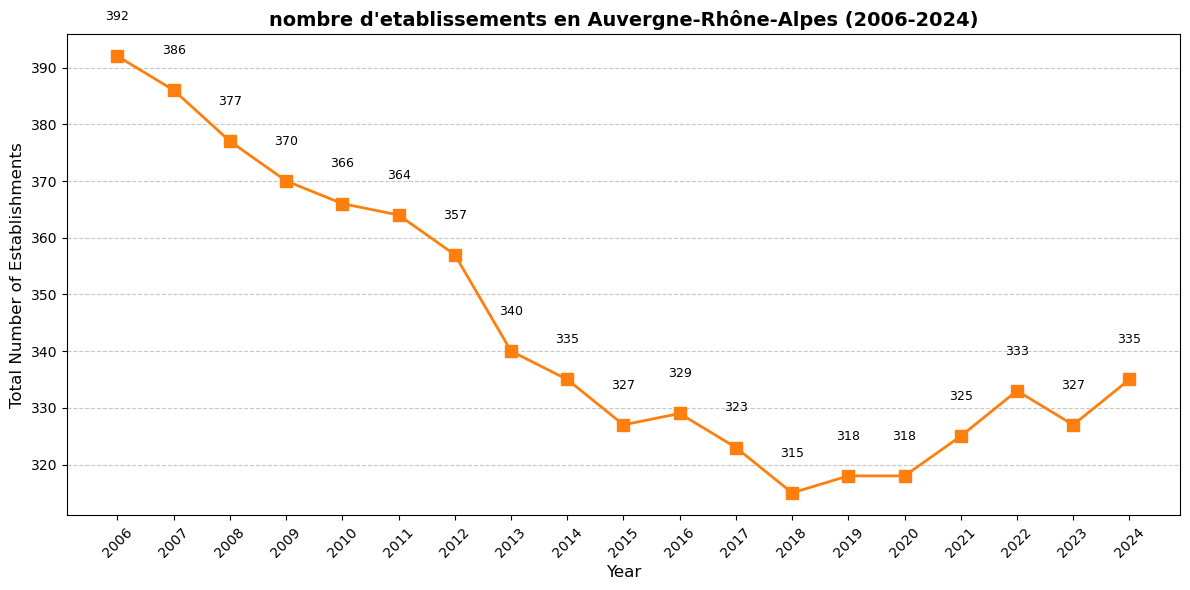

In [129]:


# 1. Load the dataset (Make sure the file name matches your local file exactly)
file_path = '../../03_data_raw/exploration_inputs/etablissements-et-effectifs-salaries-au-niveau-commune-x-ape-last.xlsx'
df = pd.read_excel(file_path)

# 2. Filter the data for the Auvergne-Rhône-Alpes region
df_ara = df[df['Région'] == 'Auvergne-Rhône-Alpes']

# 3. Extract all columns related to "Nombre d'établissements"
estab_cols = [col for col in df_ara.columns if "Nombre d'établissements" in col]

# 4. Sum the columns to get the total number of establishments per year
yearly_establishments = df_ara[estab_cols].sum()

# 5. Extract just the year from the column names (e.g., "2006" from "Nombre d'établissements 2006")
years = [int(col.split()[-1]) for col in estab_cols]
yearly_establishments.index = years

# Sort chronologically just in case the columns were out of order
yearly_establishments = yearly_establishments.sort_index()

# 6. Create the plot
plt.figure(figsize=(12, 6))

# Plot the line with square markers ('s') and a distinct orange color
plt.plot(yearly_establishments.index, yearly_establishments.values, 
         marker='s', color='#ff7f0e', linewidth=2, markersize=8)

# Format the titles, labels, and grid
plt.title("nombre d'etablissements en Auvergne-Rhône-Alpes (2006-2024)", 
          fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Total Number of Establishments', fontsize=12)
plt.xticks(years, rotation=45)
plt.grid(True, axis='y', linestyle='--', alpha=0.7)

# Add numeric data labels slightly above each point for clarity
for i, v in enumerate(yearly_establishments.values):
    plt.text(yearly_establishments.index[i], v + (max(yearly_establishments.values)*0.015), 
             f"{int(v)}", ha='center', va='bottom', fontsize=9)

# Adjust layout so everything fits nicely
plt.tight_layout()

# Display the plot
plt.show()

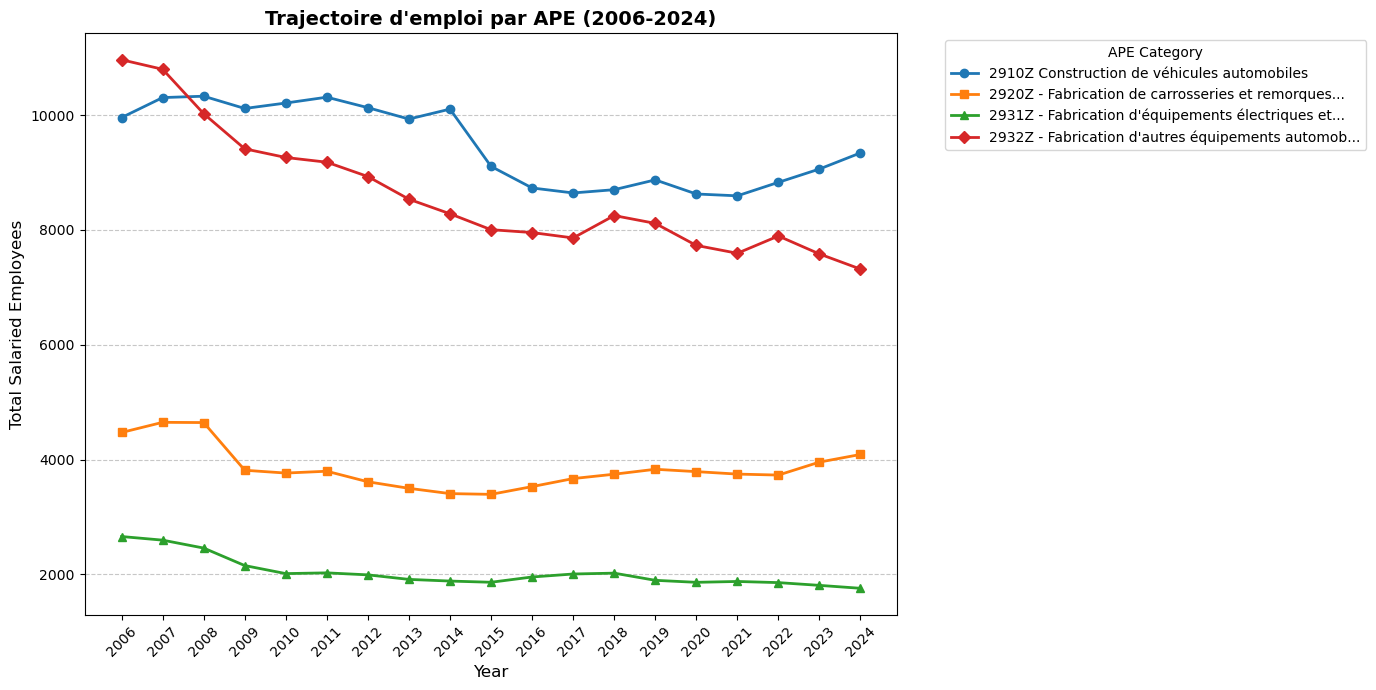

In [131]:


# 2. Filter for Auvergne-Rhône-Alpes
df_ara = df[df['Région'] == 'Auvergne-Rhône-Alpes']

# 3. Extract columns related to "Effectifs salariés" (Salaried Employment)
# Note: If you want establishments instead, change this to "Nombre d'établissements"
emp_cols = [col for col in df_ara.columns if 'Effectifs salariés' in col]

# 4. Group by 'Code APE' and sum the yearly data
ape_yearly = df_ara.groupby('Code APE')[emp_cols].sum()

# 5. Clean up the years for the X-axis (extract "2006" from "Effectifs salariés 2006")
years = [int(col.split()[-1]) for col in emp_cols]
ape_yearly.columns = years

# Transpose the data so that Years are the rows (index) and APEs are the columns
ape_yearly_t = ape_yearly.T.sort_index()

# 6. Set up the plot
plt.figure(figsize=(14, 7))
markers = ['o', 's', '^', 'D'] # Different marker shapes for visual clarity

# 7. Loop through each APE category and plot its line
for i, ape in enumerate(ape_yearly_t.columns):
    plt.plot(ape_yearly_t.index, ape_yearly_t[ape], 
             marker=markers[i % len(markers)], linewidth=2, label=ape)

# 8. Formatting the plot
plt.title("Trajectoire d'emploi par APE (2006-2024)", 
          fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Total Salaried Employees', fontsize=12)
plt.xticks(years, rotation=45)
plt.grid(True, axis='y', linestyle='--', alpha=0.7)

# 9. Create a descriptive legend (mapping APE codes to their actual names)
ape_desc = df_ara.drop_duplicates('Code APE').set_index('Code APE')['APE'].to_dict()

# Truncate very long descriptions so they fit nicely in the legend
legend_labels = [
    f"{ape} - {ape_desc[ape].split(' ', 1)[1][:40]}..." if len(ape_desc[ape]) > 45 else ape_desc[ape] 
    for ape in ape_yearly_t.columns
]

plt.legend(legend_labels, title='APE Category', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)

plt.tight_layout()

# Display the plot
plt.show()

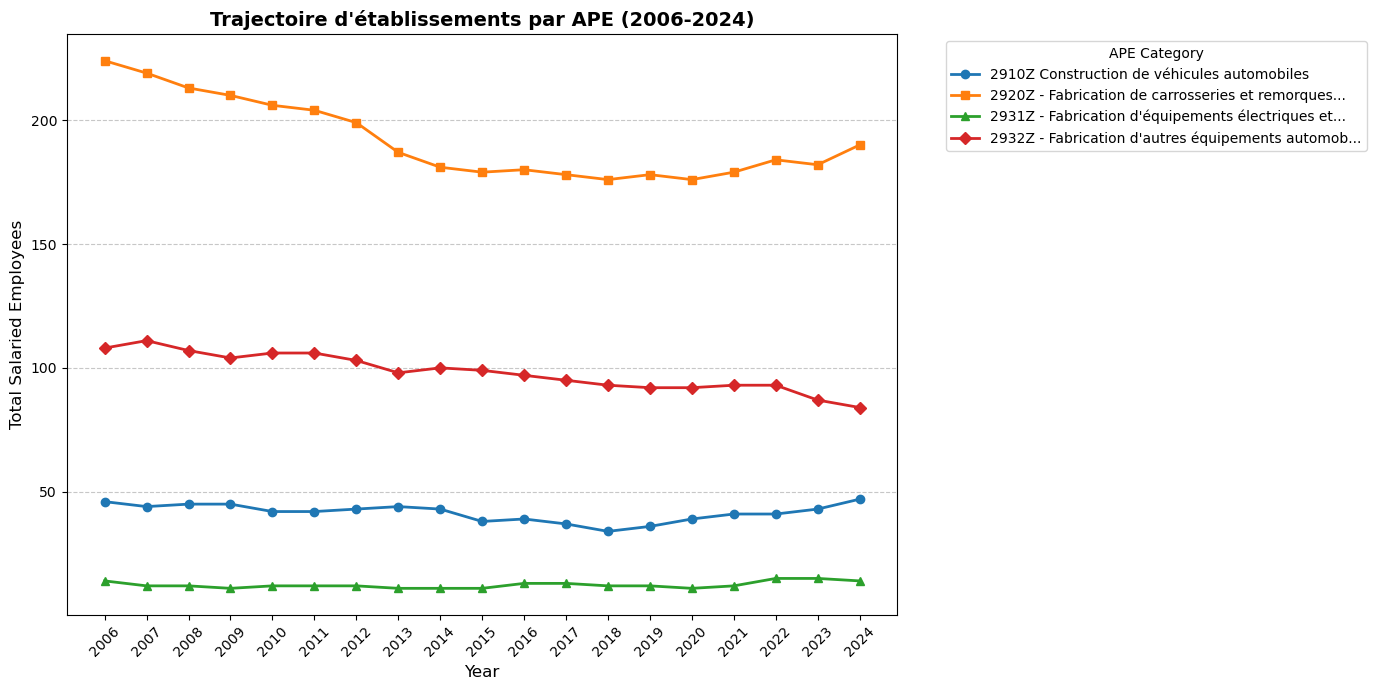

In [133]:


# 2. Filter for Auvergne-Rhône-Alpes
df_ara = df[df['Région'] == 'Auvergne-Rhône-Alpes']

# 3. Extract columns related to "Effectifs salariés" (Salaried Employment)
# Note: If you want establishments instead, change this to "Nombre d'établissements"
emp_cols = [col for col in df_ara.columns if "Nombre d'établissements" in col]

# 4. Group by 'Code APE' and sum the yearly data
ape_yearly = df_ara.groupby('Code APE')[emp_cols].sum()

# 5. Clean up the years for the X-axis (extract "2006" from "Effectifs salariés 2006")
years = [int(col.split()[-1]) for col in emp_cols]
ape_yearly.columns = years

# Transpose the data so that Years are the rows (index) and APEs are the columns
ape_yearly_t = ape_yearly.T.sort_index()

# 6. Set up the plot
plt.figure(figsize=(14, 7))
markers = ['o', 's', '^', 'D'] # Different marker shapes for visual clarity

# 7. Loop through each APE category and plot its line
for i, ape in enumerate(ape_yearly_t.columns):
    plt.plot(ape_yearly_t.index, ape_yearly_t[ape], 
             marker=markers[i % len(markers)], linewidth=2, label=ape)

# 8. Formatting the plot
plt.title("Trajectoire d'établissements par APE (2006-2024)", 
          fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Total Salaried Employees', fontsize=12)
plt.xticks(years, rotation=45)
plt.grid(True, axis='y', linestyle='--', alpha=0.7)

# 9. Create a descriptive legend (mapping APE codes to their actual names)
ape_desc = df_ara.drop_duplicates('Code APE').set_index('Code APE')['APE'].to_dict()

# Truncate very long descriptions so they fit nicely in the legend
legend_labels = [
    f"{ape} - {ape_desc[ape].split(' ', 1)[1][:40]}..." if len(ape_desc[ape]) > 45 else ape_desc[ape] 
    for ape in ape_yearly_t.columns
]

plt.legend(legend_labels, title='APE Category', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)

plt.tight_layout()

# Display the plot
plt.show()

In [136]:


# 2. Filter for a specific region
# You can change this to 'Ile de France', 'Nouvelle-Aquitaine', etc.
region_name = 'Auvergne-Rhône-Alpes'
df_region = df[df['Région'] == region_name]

# 3. Group by Commune (using both Code and Name to avoid mixing up towns with identical names)
# We use .agg() to sum up the 2024 metrics for each city
top_communes = df_region.groupby(['Département', 'Code commune', 'Nom commune']).agg(
    Total_Establishments_2024=("Nombre d'établissements 2024", 'sum'),
    Total_Employees_2024=("Effectifs salariés 2024", 'sum')
).reset_index()

# 4. Sort the results
# Here we sort by Total Employees (descending). 
# If you want to sort by Establishments, replace 'Total_Employees_2024' with 'Total_Establishments_2024'
top_communes = top_communes.sort_values(by='Total_Employees_2024', ascending=False)

# 5. Display the top 10 cities
print(top_communes.head(10).to_string(index=False))

Département Code commune           Nom commune  Total_Establishments_2024  Total_Employees_2024
      Rhône        69290          Saint-Priest                        5.0                2840.0
      Rhône        69259            Vénissieux                       10.0                2442.0
        Ain        01053       Bourg-en-Bresse                        2.0                1483.0
    Ardèche        07010               Annonay                        1.0                1212.0
      Rhône        69100                Irigny                        1.0                1044.0
    Ardèche        07324     Tournon-sur-Rhône                        1.0                 833.0
Puy-de-Dôme        63178               Issoire                        3.0                 585.0
    Ardèche        07228         Saint-Désirat                        1.0                 534.0
        Ain        01343 Saint-Cyr-sur-Menthon                        1.0                 532.0
Haute-Loire        43185        Sainte-F

In [137]:
top_communes.to_excel('/Users/majdshamashan/Downloads/top_communes.xlsx', index=False)